# EUV Stochastic Printing
Ryan Sapp · CS 427 Project 3 · November 2026

## Imports

In [1]:
import os
import numpy as np
import pandas as pd

from sklearn.model_selection import GroupKFold, KFold, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import r2_score, mean_squared_error

## Load data

In [2]:
rows_full = pd.read_csv("../data/full/rows.csv")
rows_test = pd.read_csv("../data/test/rows.csv")

print("full:", rows_full.shape)
print("test:", rows_test.shape)

full: (20160, 40)
test: (2696, 40)


## Inspect Columns

In [3]:
for c in rows_full.columns:
    print(c)

resist_id
dose_index
seed
pitch_nm
cd_target_nm
cd_ratio
mask_cd_nm
mask_bias_nm
dose_mjcm2
d0_mjcm2
dose_factor
sigma_e_nm
sigma_a_nm
sigma_q_nm
qe
rho_pag
rho_q
rho_pg
k_amp
thickness_nm
absorptivity_um
dev_threshold
na
absorbed_frac
photons_abs_per_nm2
image_peak
nils
n_holes
n_ok
n_missing
n_merged
n_merge_events
n_neighbor_pairs
p_missing
p_merged
mean_cd_nm
mean_cd_se
sigma_cd_nm
sigma_cd_se
lcdu_3s_nm


In [4]:
print(rows_full[["na", "k_amp", "sigma_q_nm"]].nunique())

na            1
k_amp         1
sigma_q_nm    1
dtype: int64


## Select features and targets

A column qualifies as a model input only if it is something that could be
set before running the process, and is not derivable from the result.
14 of the 40 columns pass, the other 26 fail one of those two tests.

| Excluded | Why |
|---|---|
| `resist_id`, `dose_index`, `seed` | Identifiers, not physical settings. `seed` is the random number generator seed |
| `cd_target_nm`, `mask_cd_nm`, `dose_mjcm2` | Already implied by features I kept. `dose_mjcm2` is `d0_mjcm2 × dose_factor`. |
| `na`, `k_amp`, `sigma_q_nm` | Identical in all 20,160 rows. A column that never varies cannot explain variation. |
| `absorbed_frac`, `photons_abs_per_nm2`, `image_peak`, `nils` | Intermediate physics the simulator computes from the settings. Including them would mean predicting the outcome from settings plus part of the answer. |
| `n_holes`, `n_ok`, `n_missing`, `n_merged`, `n_merge_events`, `n_neighbor_pairs`, `p_merged` | Simulation outputs. Using one output to predict another is leakage. |
| `mean_cd_se`, `sigma_cd_se`, `lcdu_3s_nm` | Derived from the targets themselves — `lcdu_3s_nm` is `3 × sigma_cd_nm`. |

The 14 that remain are exactly the quantities an engineer chooses before
exposing a wafer, which is what makes the trained model usable as a
substitute for running the simulator.

In [5]:
FEATURES = [
    "pitch_nm", "cd_ratio", "mask_bias_nm", "d0_mjcm2",
    "sigma_e_nm", "sigma_a_nm", "qe", "rho_pag", "rho_pg",
    "thickness_nm", "absorptivity_um", "dev_threshold",
    "rho_q",
    "dose_factor",
]

TARGETS = ["p_missing", "mean_cd_nm", "sigma_cd_nm"]

## Build film keys and check for collisions

In [6]:
rows_full["run"] = "full"
rows_test["run"] = "test"

for df in (rows_full, rows_test):
    df["resist_key"] = df["run"] + "_" + df["resist_id"].astype(str)

# resist ids restart at 0 in each run, so the raw ids collide; the combined key must not
raw_shared = len(set(rows_full["resist_id"]) & set(rows_test["resist_id"]))
key_shared = len(set(rows_full["resist_key"]) & set(rows_test["resist_key"]))

print("full resists:", rows_full["resist_key"].nunique())
print("test resists:", rows_test["resist_key"].nunique())
print("resist ids found in both files:", raw_shared)
print("combined keys found in both files:", key_shared)

full resists: 2520
test resists: 337
resist ids found in both files: 283
combined keys found in both files: 0


## Separate training and test data sets

In [7]:
train = rows_full
test  = rows_test

print("train:", train.shape, "| test:", test.shape)

train: (20160, 42) | test: (2696, 42)


## Define targets and row filters

In [8]:
def masks_for(df):
    return {
        # every row has a failure rate, so this mask keeps all of them
        "p_missing":   pd.Series(True, index=df.index),

        # mean size needs at least one usable hole (not missing, not merged)
        "mean_cd_nm":  df["n_ok"] > 0,

        # a standard deviation from under 100 holes is too noisy to learn from
        "sigma_cd_nm": df["n_ok"] >= 100,
    }

MASKS = masks_for(train)

for t, m in MASKS.items():
    print(f"rows for {t:14s} {m.sum()}")

print("\nrows with no usable hole:", (train["n_ok"] == 0).sum())
print("mean_cd_nm missing:", train["mean_cd_nm"].isna().sum())

rows for p_missing      20160
rows for mean_cd_nm     20114
rows for sigma_cd_nm    19909

rows with no usable hole: 46
mean_cd_nm missing: 46


## Transform inputs

**The inputs.** Thirteen of the 14 settings get a log transform. These are
quantities where changes act by multiplication rather than addition (doubling
the acid-generator concentration roughly doubles its effect, it doesn't add a
fixed amount). Taking logs turns "multiply by 2" into "add a constant", which is
the kind of relationship a linear model can represent. The exception is
mask_bias_nm. This is a length added to the drawn hole size. It already acts by
addition, so logging it would distort it rather than help.

**The failure-rate target.** p_missing is modelled as log10(p + EPS) rather than
raw. Failure rates in this dataset run from 1-in-1,800 up to nearly
everything failing. On a raw scale, almost all of a model's score comes from
telling 10% apart from 50%, and it gets essentially no credit for telling 0.1%
apart from 0.01%. For chip manufacturing the second distinction is very 
important, as it's the difference between a usable process and a dead one. The
log scale makes the model care about both equally.

**Why EPS.** About three quarters of rows printed every hole successfully. This gives a failure rate of
zero, and log(0) is undefined. EPS is half of the smallest rate the
simulation could have detected (1 hole in 1800). Adding it means a zero reads as
"below the detection limit" instead of breaking the calculation.

In [9]:
print(train[FEATURES].min())

pitch_nm           32.000000
cd_ratio            0.420016
mask_bias_nm        0.001276
d0_mjcm2           20.001136
sigma_e_nm          1.200149
sigma_a_nm          4.000435
qe                  2.000203
rho_pag             0.120011
rho_pg              1.500444
thickness_nm       30.010655
absorptivity_um     4.200338
dev_threshold       0.350096
rho_q               0.012274
dose_factor         0.600078
dtype: float64


In [10]:
LOG_FEATURES = [f for f in FEATURES if f != "mask_bias_nm"]

HOLES_PER_ROW = train["n_holes"].iloc[0]
EPS = 1 / (2 * HOLES_PER_ROW)

def make_X(df):
    X = df[FEATURES].copy()
    X[LOG_FEATURES] = np.log(X[LOG_FEATURES])
    return X

def make_y(df, target):
    if target == "p_missing":
        return np.log10(df["p_missing"] + EPS)
    return df[target]

X_train = make_X(train)
print(X_train.shape, "|", X_train.isna().values.sum(), "NaNs")

(20160, 14) | 0 NaNs


## Cross-validation setup

In [11]:
groups = train["resist_key"]
cv = GroupKFold(n_splits=5)

MODELS = {
    "Linear": LinearRegression(),
    "Random forest": RandomForestRegressor(
        n_estimators=200, min_samples_leaf=5, random_state=0, n_jobs=-1),
    "Neural net": MLPRegressor(
        hidden_layer_sizes=(64, 64), alpha=1e-3, max_iter=1000, random_state=0),
}

# no resist should have rows on both sides of a fold
for fold, (train_idx, test_idx) in enumerate(cv.split(X_train, groups=groups)):
    train_resists = groups.iloc[train_idx]
    test_resists = groups.iloc[test_idx]
    shared_rows = test_resists.isin(train_resists).sum()
    print(f"fold {fold}: {len(train_idx)} train rows, {len(test_idx)} test rows, {shared_rows} shared")

fold 0: 16128 train rows, 4032 test rows, 0 shared
fold 1: 16128 train rows, 4032 test rows, 0 shared
fold 2: 16128 train rows, 4032 test rows, 0 shared
fold 3: 16128 train rows, 4032 test rows, 0 shared
fold 4: 16128 train rows, 4032 test rows, 0 shared


## Train and compare

In [12]:
results = []
scores = {}

for target in TARGETS:
    rows = train[MASKS[target]]
    X = make_X(rows)
    y = make_y(rows, target)
    film_ids = rows["resist_key"]

    for name, model in MODELS.items():
        pipe = Pipeline([("scale", StandardScaler()), ("model", model)])
        yhat = cross_val_predict(pipe, X, y, groups=film_ids, cv=cv)

        r2 = r2_score(y, yhat)
        rmse = np.sqrt(mean_squared_error(y, yhat))

        results.append({"target": target, "model": name, "r2": r2, "rmse": rmse})
        scores[(target, name)] = r2

        print(f"{target:14s} {name:14s} R2={r2:7.4f}  RMSE={rmse:.4f}")

results_df = pd.DataFrame(results)

p_missing      Linear         R2= 0.5011  RMSE=0.7429
p_missing      Random forest  R2= 0.9737  RMSE=0.1704
p_missing      Neural net     R2= 0.9864  RMSE=0.1227
mean_cd_nm     Linear         R2= 0.9809  RMSE=1.1053
mean_cd_nm     Random forest  R2= 0.9960  RMSE=0.5066
mean_cd_nm     Neural net     R2= 0.9996  RMSE=0.1693
sigma_cd_nm    Linear         R2= 0.7186  RMSE=0.1964
sigma_cd_nm    Random forest  R2= 0.9463  RMSE=0.0858
sigma_cd_nm    Neural net     R2= 0.9760  RMSE=0.0573


## Held-out test set

In [13]:
test_masks = masks_for(test)
heldout = []
heldout_models = {}

for target in TARGETS:
    train_rows = train[MASKS[target]]
    test_rows = test[test_masks[target]]

    X_tr = make_X(train_rows)
    y_tr = make_y(train_rows, target)
    X_te = make_X(test_rows)
    y_te = make_y(test_rows, target)

    for name, model in MODELS.items():
        pipe = Pipeline([("scale", StandardScaler()), ("model", clone(model))])
        pipe.fit(X_tr, y_tr)
        heldout_models[(target, name)] = pipe
        yhat = pipe.predict(X_te)

        r2 = r2_score(y_te, yhat)
        rmse = np.sqrt(mean_squared_error(y_te, yhat))

        heldout.append({"target": target, "model": name,
                        "r2": r2, "rmse": rmse, "n_test": len(y_te)})

        print(f"{target:14s} {name:14s} R2={r2:7.4f}  n={len(y_te)}")

heldout_df = pd.DataFrame(heldout)

p_missing      Linear         R2= 0.5027  n=2696
p_missing      Random forest  R2= 0.9743  n=2696
p_missing      Neural net     R2= 0.9892  n=2696
mean_cd_nm     Linear         R2= 0.9810  n=2692
mean_cd_nm     Random forest  R2= 0.9963  n=2692
mean_cd_nm     Neural net     R2= 0.9997  n=2692
sigma_cd_nm    Linear         R2= 0.7192  n=2659
sigma_cd_nm    Random forest  R2= 0.9453  n=2659
sigma_cd_nm    Neural net     R2= 0.9815  n=2659


## Failure-rate error where holes actually went missing

About three quarters of rows have no missing holes, and the models predict those
easily. Averaging over all rows therefore flatters the failure-rate error, so it is
shown here for all rows, rows with no missing holes, and rows where holes did go missing.
The last lines measure how sharply the failure rate changes between a resist's neighboring doses.
`factor` is 10 to the power of the RMSE: the typical factor a prediction is off by.

In [14]:
none_missing = test["p_missing"] == 0
X_te, y_te = make_X(test), make_y(test, "p_missing")
groups = (("all rows", none_missing | ~none_missing),
          ("no missing holes", none_missing),
          ("holes went missing", ~none_missing))

print(f"held-out rows with no missing holes: {none_missing.mean():.1%}")

failure_split = []
for name in MODELS:
    yhat = heldout_models[("p_missing", name)].predict(X_te)

    for rows_label, m in groups:
        rmse = np.sqrt(mean_squared_error(y_te[m], yhat[m]))
        # R2 is meaningless where every true value is the same (the detection floor)
        r2 = np.nan if rows_label == "no missing holes" else r2_score(y_te[m], yhat[m])
        failure_split.append({"model": name, "rows": rows_label, "n": int(m.sum()),
                              "rmse": rmse, "factor": 10 ** rmse, "r2": r2})
        print(f"{name:14s} {rows_label:19s} n={m.sum():5d}  RMSE={rmse:.4f}  factor={10 ** rmse:.2f}"
              + ("" if np.isnan(r2) else f"  R2={r2:.4f}"))

failure_split_df = pd.DataFrame(failure_split)

# how sharply the failure rate changes between neighboring doses of the same resist
jumps = []
for _, d in train.sort_values("dose_factor").groupby("resist_key"):
    pm = d["p_missing"].to_numpy()
    both = (pm[:-1] > 0) & (pm[1:] > 0)
    jumps.extend(pm[:-1][both] / pm[1:][both])
jumps = np.array(jumps)
print(f"\nneighboring doses with failures at both: {len(jumps):,} pairs; going down one dose step "
      f"multiplies the failure rate by a median of {np.median(jumps):.0f}x (at least 10x in {(jumps >= 10).mean():.0%})")

held-out rows with no missing holes: 76.4%
Linear         all rows            n= 2696  RMSE=0.7401  factor=5.50  R2=0.5027
Linear         no missing holes    n= 2059  RMSE=0.6167  factor=4.14
Linear         holes went missing  n=  637  RMSE=1.0434  factor=11.05  R2=-0.0795
Random forest  all rows            n= 2696  RMSE=0.1683  factor=1.47  R2=0.9743
Random forest  no missing holes    n= 2059  RMSE=0.1011  factor=1.26
Random forest  holes went missing  n=  637  RMSE=0.2946  factor=1.97  R2=0.9140
Neural net     all rows            n= 2696  RMSE=0.1090  factor=1.29  R2=0.9892
Neural net     no missing holes    n= 2059  RMSE=0.0762  factor=1.19
Neural net     holes went missing  n=  637  RMSE=0.1775  factor=1.50  R2=0.9688

neighboring doses with failures at both: 2,417 pairs; going down one dose step multiplies the failure rate by a median of 18x (at least 10x in 65%)


## Predicted vs actual on the held-out set

Each point is one held-out recipe; points on the diagonal are perfect predictions.
The failure-rate panel is in log units, so the column of points at the left is the
rows with no missing holes, all sitting at the detection floor.

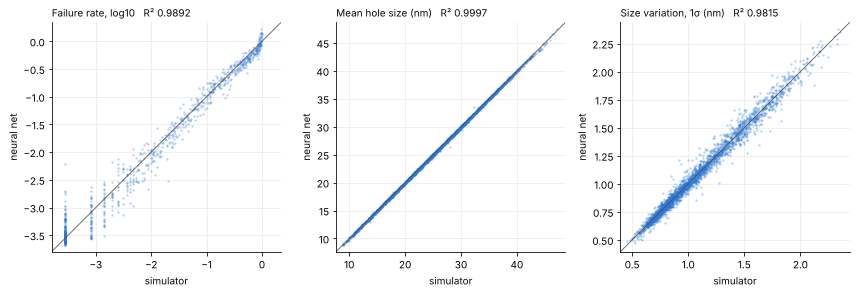

In [15]:
import matplotlib.pyplot as plt

BLUE, INK, INK2, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e7e6e2"
panels = {"p_missing": "Failure rate, log10",
          "mean_cd_nm": "Mean hole size (nm)",
          "sigma_cd_nm": "Size variation, 1σ (nm)"}

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, target in zip(axes, TARGETS):
    rows = test[test_masks[target]]
    y = make_y(rows, target)
    yhat = heldout_models[(target, "Neural net")].predict(make_X(rows))

    lo, hi = min(y.min(), yhat.min()), max(y.max(), yhat.max())
    pad = 0.03 * (hi - lo)
    ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], color=INK2, lw=0.8)
    ax.scatter(y, yhat, s=5, color=BLUE, alpha=0.35, linewidths=0)
    ax.set_xlim(lo - pad, hi + pad); ax.set_ylim(lo - pad, hi + pad); ax.set_aspect("equal")
    ax.set_title(f"{panels[target]}   R² {r2_score(y, yhat):.4f}", loc="left", fontsize=10, color=INK)
    ax.set_xlabel("simulator", color=INK); ax.set_ylabel("neural net", color=INK)
    ax.grid(color=GRID, lw=0.6); ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

fig.tight_layout()
os.makedirs("../results/ml", exist_ok=True)
fig.savefig("../results/ml/heldout_parity.png", dpi=200)
plt.show()

## Leakage measurement

In [16]:
cv_random = KFold(n_splits=5, shuffle=True, random_state=0)

leakage = []
for target in TARGETS:
    rows = train[MASKS[target]]
    X = make_X(rows)
    y = make_y(rows, target)

    for name, model in MODELS.items():
        pipe = Pipeline([("scale", StandardScaler()), ("model", model)])
        # deliberately no groups= here: that is what this cell measures
        yhat_random = cross_val_predict(pipe, X, y, cv=cv_random)

        r2_random = r2_score(y, yhat_random)
        r2_grouped = scores[(target, name)]

        leakage.append({"target": target, "model": name,
                        "grouped": r2_grouped, "random": r2_random,
                        "difference": r2_random - r2_grouped})

        print(f"{target:14s} {name:14s} grouped={r2_grouped:.4f}  random={r2_random:.4f}")

leakage_df = pd.DataFrame(leakage)

p_missing      Linear         grouped=0.5011  random=0.5004
p_missing      Random forest  grouped=0.9737  random=0.9740
p_missing      Neural net     grouped=0.9864  random=0.9869
mean_cd_nm     Linear         grouped=0.9809  random=0.9809
mean_cd_nm     Random forest  grouped=0.9960  random=0.9962
mean_cd_nm     Neural net     grouped=0.9996  random=0.9997
sigma_cd_nm    Linear         grouped=0.7186  random=0.7186
sigma_cd_nm    Random forest  grouped=0.9463  random=0.9501
sigma_cd_nm    Neural net     grouped=0.9760  random=0.9803


## Speed: simulator vs neural network

The report compares the cost of one simulated recipe with one prediction, so both are
measured here. The simulator is timed on 20 real recipes from the dataset at their
standard dose, with the dataset's 1,800 holes each. Times depend on the machine.

In [17]:
import sys, time
from dataclasses import replace

sys.path.insert(0, os.path.abspath("../sim"))
import make_dataset as md
from simulator_v2 import simulate

recipes = train[train["dose_factor"] == 1.0].sample(20, random_state=0)
sim_seconds = []
for _, r in recipes.iterrows():
    p = replace(md.to_params(r.to_dict()), rho_q=r["rho_q"])
    t0 = time.perf_counter()
    simulate(p, 200, np.random.default_rng(0))   # 200 tiles x 9 holes = 1,800 holes
    sim_seconds.append(time.perf_counter() - t0)
sim_seconds = np.array(sim_seconds)

# a failure rate of 1 in a million needs about 3 million holes to expect even 3 failures
rare_hours = 3_000_000 / 1800 * sim_seconds / 3600

nn = heldout_models[("p_missing", "Neural net")]
X_batch = pd.concat([make_X(train)] * 10, ignore_index=True)
t0 = time.perf_counter(); nn.predict(X_batch); batch_us = (time.perf_counter() - t0) / len(X_batch) * 1e6
X_one = make_X(train.iloc[[0]])
t0 = time.perf_counter()
for _ in range(200):
    nn.predict(X_one)
single_ms = (time.perf_counter() - t0) / 200 * 1e3

timing_df = pd.DataFrame([
    {"measure": "simulator, seconds per 1,800-hole recipe (median)", "value": np.median(sim_seconds)},
    {"measure": "simulator, seconds per 1,800-hole recipe (min)", "value": sim_seconds.min()},
    {"measure": "simulator, seconds per 1,800-hole recipe (max)", "value": sim_seconds.max()},
    {"measure": "simulator, hours for 3 million holes (median)", "value": np.median(rare_hours)},
    {"measure": "neural net, microseconds per recipe in a batch", "value": batch_us},
    {"measure": "neural net, milliseconds for a single call", "value": single_ms},
])
print(f"simulator: {np.median(sim_seconds):.2f} s per recipe (range {sim_seconds.min():.2f}-{sim_seconds.max():.2f}), "
      f"{np.median(rare_hours):.2f} h for 3 million holes")
print(f"neural net: {batch_us:.2f} us per recipe over {len(X_batch):,} recipes, {single_ms:.2f} ms for a single call")
print(f"machine: {os.cpu_count()} logical cores")

simulator: 1.87 s per recipe (range 0.64-2.73), 0.86 h for 3 million holes
neural net: 1.03 us per recipe over 201,600 recipes, 0.79 ms for a single call
machine: 2 logical cores


## Save Results

In [18]:
os.makedirs("../results/ml", exist_ok=True)

results_df.to_csv("../results/ml/cv_scores.csv", index=False)
leakage_df.to_csv("../results/ml/leakage_comparison.csv", index=False)
heldout_df.to_csv("../results/ml/heldout_scores.csv", index=False)
failure_split_df.to_csv("../results/ml/heldout_failure_split.csv", index=False)
timing_df.to_csv("../results/ml/timing.csv", index=False)

print("saved to results/ml/")

saved to results/ml/
